d:\GIT\Teaching Material\2025-26\3rd Sem\DIP Lab - AIML\Source Code\Expt 9\Images


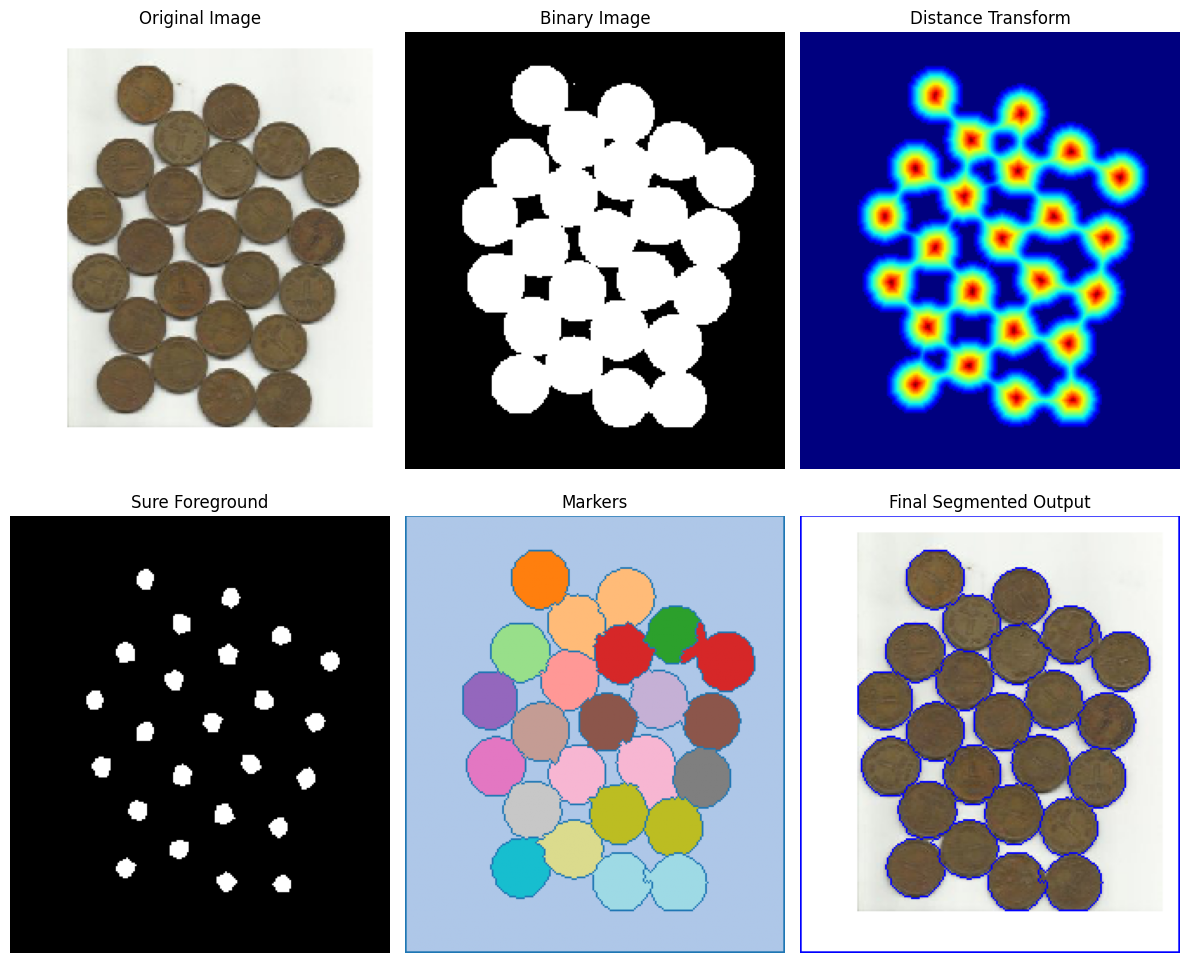

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import pathlib

# Set image path
image_path = pathlib.Path(os.path.join(os.getcwd(), "Images"))
print(image_path)

# Read the image
img = cv2.imread(image_path / "overlapping_coins.png")
if img is None:
    raise FileNotFoundError("Input image not found.")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Apply thresholding
_, thresh = cv2.threshold(gray, 0, 255,
                           cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Noise removal using morphological opening
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# Sure background area
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Distance transform
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)

# Sure foreground area
_, sure_fg = cv2.threshold(dist_transform,
                            0.7 * dist_transform.max(),
                            255, 0)
sure_fg = np.uint8(sure_fg)

# Unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

# Marker labeling
_, markers = cv2.connectedComponents(sure_fg)

# Add 1 to all labels so background is not 0
markers = markers + 1

# Mark unknown region with 0
markers[unknown == 255] = 0

# Apply watershed
markers = cv2.watershed(img, markers)

# Mark watershed boundaries in red
segmented_img = img.copy()
segmented_img[markers == -1] = [255, 0, 0]

# Display results
plt.figure(figsize=(12, 10))

plt.subplot(2, 3, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")

plt.subplot(2, 3, 2)
plt.title("Binary Image")
plt.imshow(thresh, cmap="gray")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.title("Distance Transform")
plt.imshow(dist_transform, cmap="jet")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.title("Sure Foreground")
plt.imshow(sure_fg, cmap="gray")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.title("Markers")
plt.imshow(markers, cmap="tab20")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.title("Final Segmented Output")
plt.imshow(cv2.cvtColor(segmented_img, cv2.COLOR_BGR2RGB))
plt.axis("off")

plt.tight_layout()
plt.show()
